In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import InMemoryVectorStore
from langchain_groq import ChatGroq

from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field

C:\Users\Pc\AppData\Local\Temp\ipykernel_7044\863202415.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [3]:
## Documents Load
loader = PyPDFLoader("../data/GenAI_Interview_Notes.pdf")
docs = loader.load()

In [4]:
## Splitting Text Into Chunks
splitter = RecursiveCharacterTextSplitter(chunk_size = 1000 ,chunk_overlap = 200 )
docs_chunks = splitter.split_documents(docs)

In [5]:
## vector embeddings
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)


c:\Users\Pc\Desktop\GENAI_Series\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 866.02it/s]


In [7]:
## vector store and chunks
vector_store = InMemoryVectorStore.from_documents(
    documents = docs_chunks,
    embedding = embeddings
)


In [8]:
llm = ChatGroq(model = "openai/gpt-oss-20b")

In [9]:
class RagState(BaseModel):
    question: str = Field(description ="User Question")
    documents: list = []
    context : str = Field(description= "Context Data for user question",default = "")
    answer : str = Field(description = "Final Answer....", default = "")

In [10]:
def retrieve_node(state:RagState) -> RagState :
    document = vector_store.similarity_search(query = state.question)
    state.documents = document
    return state

def create_context_node(state:RagState)-> RagState :
    context = ""
    for doc in state.documents:
        context += doc.page_content + "\n\n"
    state.context = context
    return state

def generate_node(state:RagState) -> RagState:
    prompt = f"""
    You are a assistant and provide the answer for user question based on the provided context.
    If you don't find the relevant answer, then just say 'I don't know.'
    Context is : {state.context}
    Questions is : {state.question}
    """
    res = llm.invoke(prompt)
    state.answer = res.content # type:ignore
    return state

In [11]:
graph = StateGraph(RagState)

graph.add_node("retrieve_node", retrieve_node)
graph.add_node("create_context_node", create_context_node)
graph.add_node("generate_node", generate_node)

graph.add_edge(START, 'retrieve_node')
graph.add_edge('retrieve_node', 'create_context_node')
graph.add_edge('create_context_node', "generate_node")
graph.add_edge('generate_node', END)

graph = graph.compile()

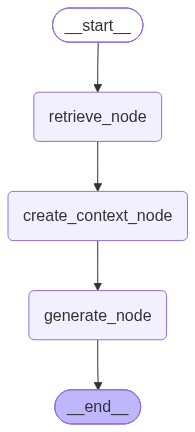

In [13]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [23]:
res = graph.invoke({"question":"What is RAG ?"})

In [24]:
print(res['answer'])

**RAG (Retrieval‑Augmented Generation)** is a framework that combines a large language model (LLM) with an external knowledge source—typically a vector‑based document database.  
- **Retrieval step**: The user’s query is turned into an embedding, which is used to search the vector database for the most semantically relevant document chunks.  
- **Generation step**: Those retrieved chunks are concatenated with the original query and fed into the LLM, which then produces an answer grounded in the up‑to‑date, domain‑specific information it has just “seen.”  

RAG allows the model to access fresh facts at query time without retraining, reducing hallucinations and keeping answers current.
